# 03 Feature matrix: sanity checks and figures (slice 3)

Checks the matrix built by `src/prepare.py` and `src/features.py` (see `docs/data_dictionary.md`): how every feature looks for benign and tunnel traffic, which benign queries come closest to the tunnel, how the tunnel phases differ, and how far the test period drifts away from the training period.

Default run: `session="second"` (burst 2 is the tunnel session, burst 1 is removed from the stream), train before 18:30 UTC, 60 s window. The strict variant (`session="first"`, cut 18:04:36) is compared in section 5.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import make_matrix, feature_sets, drift_table

pd.set_option("display.width", 200)
m = make_matrix(session="second", window_s=60, write=False)
fs = feature_sets(60)
FEATS = fs["full"]
print(m.shape)
print(m.groupby(["split", "label"]).size().unstack(fill_value=0))
print("missing values in features:", int(m[FEATS].isna().sum().sum()))

(3423, 18)
label  benign  tunnel
split                
test     1609     222
train    1592       0
missing values in features: 0


## 1. Every feature, benign against tunnel

Median, 95th percentile and maximum per label.

In [2]:
summary = m.groupby("label")[FEATS].agg(["median", lambda s: s.quantile(.95), "max"])
summary.columns = [f"{c} {s if isinstance(s, str) else 'p95'}" for c, s in summary.columns]
summary.T.round(2)

label,benign,tunnel
name_bytes median,20.00,19.00
name_bytes <lambda_0>,51.00,252.00
name_bytes max,103.00,252.00
longest_label median,9.00,8.00
longest_label <lambda_0>,17.00,62.00
longest_label max,57.00,62.00
entropy median,2.50,2.75
entropy <lambda_0>,4.32,5.62
entropy max,4.53,6.30
uniq_names_60s median,1.00,111.50


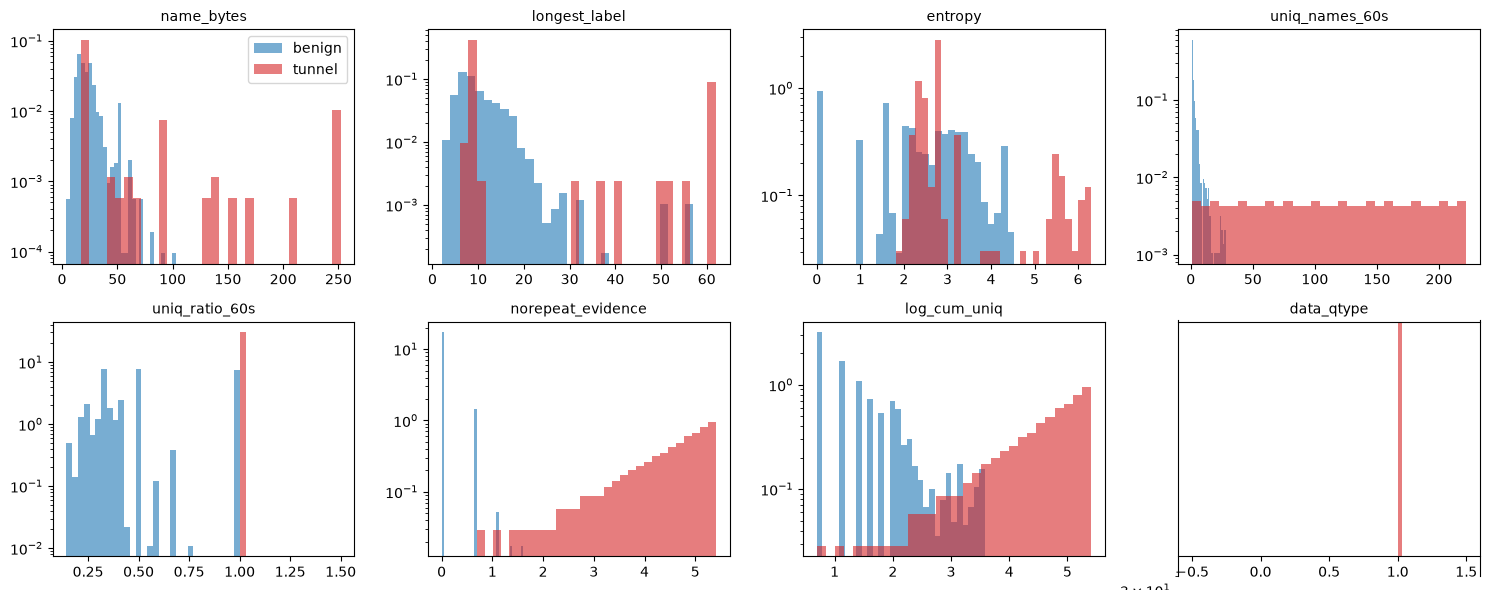

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.ravel(), FEATS):
    for lab, color in [("benign", "tab:blue"), ("tunnel", "tab:red")]:
        ax.hist(m.loc[m.label == lab, col], bins=30, alpha=.6, color=color, label=lab, density=True)
    ax.set_title(col, fontsize=10); ax.set_yscale("log")
axes[0, 0].legend(); plt.tight_layout(); plt.show()

## 2. Per-query shape against domain context, by tunnel phase

173 of the 222 tunnel queries are pings with short names. Per phase, the shape features of a ping look normal, while the context features still separate it.

In [4]:
by_phase = m.groupby("phase")[FEATS].median().round(2)
by_phase["queries"] = m.groupby("phase").size()
by_phase.loc[["benign", "ping", "data", "size_probe", "handshake", "encoding_test"]]

,name_bytes,longest_label,entropy,uniq_names_60s,uniq_ratio_60s,norepeat_evidence,log_cum_uniq,data_qtype,queries
phase,,,,,,,,,
benign,20.0,9.0,2.50,1.0,0.4,0.00,1.39,0.0,3201
ping,19.0,8.0,2.75,133.0,1.0,4.90,4.90,1.0,173
data,93.5,62.0,5.56,40.0,1.0,3.71,3.71,1.0,24
size_probe,252.0,62.0,3.22,18.0,1.0,2.94,2.94,1.0,13
handshake,22.0,11.0,2.95,2.0,1.0,1.10,1.10,1.0,3
encoding_test,47.0,36.0,3.88,7.0,1.0,2.08,2.08,1.0,9


In [5]:
# How many tunnel queries would a simple threshold on one feature catch? (illustration only, not the detector)
tun = m[m.y == 1]
ben = m[m.y == 0]
rows = []
for col, thr in [("entropy", 4.0), ("name_bytes", 63), ("uniq_names_60s", 30), ("uniq_ratio_60s", 0.99)]:
    rows.append({"feature": col, "threshold": thr, "tunnel rows above": int((tun[col] > thr).sum()),
                 "benign rows above": int((ben[col] > thr).sum())})
pd.DataFrame(rows)

,feature,threshold,tunnel rows above,benign rows above
0,entropy,4.00,28,201
1,name_bytes,63.00,38,16
2,uniq_names_60s,30.00,192,0
3,uniq_ratio_60s,0.99,222,689


## 3. Benign look-alikes

The benign queries that score highest on each feature. These are the likely false positives.

In [6]:
show = ["parent", "name", "name_bytes", "entropy", "uniq_names_60s", "uniq_ratio_60s", "norepeat_evidence"]
from src.prepare import load_raw, prepare
prep = prepare(load_raw(), session="second")
mm = m.assign(name=prep["name"].to_numpy())
b = mm[mm.y == 0]
for col in ["uniq_names_60s", "entropy", "name_bytes", "norepeat_evidence"]:
    print(f"--- highest benign {col}")
    display(b.nlargest(5, col)[show].assign(name=lambda d: d["name"].str[:60]))

--- highest benign uniq_names_60s


,parent,name,name_bytes,entropy,uniq_names_60s,uniq_ratio_60s,norepeat_evidence
2406,yahoo.com,graphite.sports.yahoo.com,25,3.373557,28.0,0.247788,0.0
2407,yahoo.com,graphite.sports.yahoo.com,25,3.373557,28.0,0.245614,0.0
2408,yahoo.com,graphite.sports.yahoo.com,25,3.373557,28.0,0.243478,0.0
2422,yahoo.com,graphite.sports.yahoo.com,25,3.373557,28.0,0.241379,0.0
2423,yahoo.com,graphite.sports.yahoo.com,25,3.373557,28.0,0.239316,0.0


--- highest benign entropy


,parent,name,name_bytes,entropy,uniq_names_60s,uniq_ratio_60s,norepeat_evidence
2758,akamaihd.net,slyvk6sqincawy5zx5fa-pw2lcn-4b611d2b3-clientns...,63,4.533661,4.0,0.400000,0.000000
2759,akamaihd.net,slyvk6sqincawy5zx5fa-pw2lcn-4b611d2b3-clientns...,63,4.533661,4.0,0.363636,0.000000
2760,akamaihd.net,slyvk6sqincawy5zx5fa-pw2lcn-4b611d2b3-clientns...,63,4.533661,4.0,0.333333,0.000000
3102,go.com,_9573._https.pe80430c73-cc46-4682-a0b2-e867b33...,93,4.471761,6.0,0.375000,0.000000
52,akadns.net,188224-ipv4v6e.farm.dprodmgd104.sharepointonli...,63,4.468919,1.0,1.000000,0.693147


--- highest benign name_bytes


,parent,name,name_bytes,entropy,uniq_names_60s,uniq_ratio_60s,norepeat_evidence
900,office.net,ic3-unified-presence-service-presence.westeuro...,103,3.789438,1.0,1.000000,0.693147
3102,go.com,_9573._https.pe80430c73-cc46-4682-a0b2-e867b33...,93,4.471761,6.0,0.375000,0.000000
3100,go.com,pe80430c73-cc46-4682-a0b2-e867b33316be-54-90-1...,80,4.324247,5.0,0.357143,0.000000
3101,go.com,pe80430c73-cc46-4682-a0b2-e867b33316be-54-90-1...,80,4.324247,5.0,0.333333,0.000000
2755,akamaihd.net,146-241-85-122_s-78-134-83-209_ts-1673117514-c...,70,3.933963,3.0,0.428571,0.000000


--- highest benign norepeat_evidence


,parent,name,name_bytes,entropy,uniq_names_60s,uniq_ratio_60s,norepeat_evidence
44,dropbox.com,client.dropbox.com,18,2.584963,3.0,1.0,1.609438
87,azure.com,onedscolprdneu05.northeurope.cloudapp.azure.com,47,3.787043,1.0,1.0,1.609438
1495,akamaiedge.net,e15275.g.akamaiedge.net,23,2.750000,1.0,1.0,1.609438
43,dropbox.com,bolt.dropbox.com,16,2.000000,2.0,1.0,1.386294
80,azure.com,onedscolprdcus14.centralus.cloudapp.azure.com,45,3.799874,1.0,1.0,1.386294


## 4. The start of the tunnel session

Context features need evidence to build up. The first queries of the session look like a new benign domain.

In [7]:
first_rows = m[m.y == 1].head(12)[["phase", "name_bytes", "entropy", "uniq_names_60s", "uniq_ratio_60s", "norepeat_evidence"]]
first_rows.round(2)

,phase,name_bytes,entropy,uniq_names_60s,uniq_ratio_60s,norepeat_evidence
2246,handshake,22,2.40,1.0,1.0,0.69
2247,handshake,43,4.16,2.0,1.0,1.10
2248,encoding_test,17,2.58,3.0,1.0,1.39
2249,encoding_test,52,3.88,4.0,1.0,1.61
2250,encoding_test,61,3.97,5.0,1.0,1.79
2251,encoding_test,67,4.78,6.0,1.0,1.95
2252,encoding_test,47,4.98,7.0,1.0,2.08
2253,encoding_test,63,5.66,8.0,1.0,2.20
2254,encoding_test,17,2.58,9.0,1.0,2.30
2255,encoding_test,17,2.58,10.0,1.0,2.40


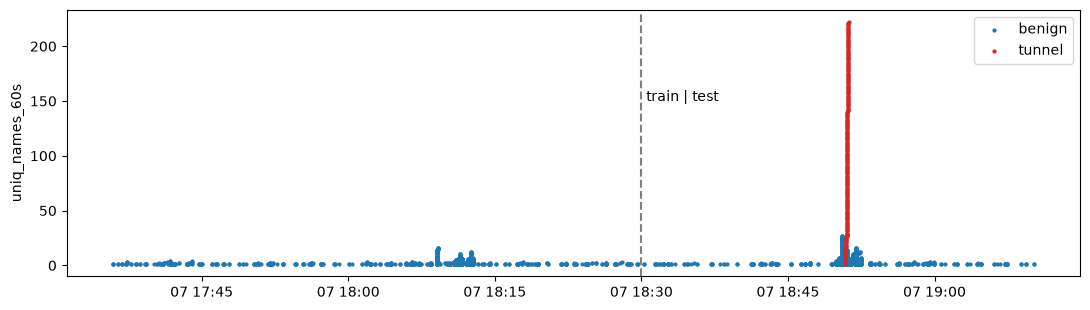

In [8]:
# Timeline of uniq_names_60s: tunnel session against the busiest benign domains
fig, ax = plt.subplots(figsize=(11, 3.2))
m["dt"] = pd.to_datetime(m["ts"], unit="s")
ax.scatter(m.loc[m.y == 0, "dt"], m.loc[m.y == 0, "uniq_names_60s"], s=4, color="tab:blue", label="benign")
ax.scatter(m.loc[m.y == 1, "dt"], m.loc[m.y == 1, "uniq_names_60s"], s=4, color="tab:red", label="tunnel")
ax.axvline(pd.Timestamp("2023-01-07 18:30"), color="gray", ls="--"); ax.text(pd.Timestamp("2023-01-07 18:30:30"), 150, "train | test")
ax.set_ylabel("uniq_names_60s"); ax.legend(); plt.tight_layout(); plt.show()

## 5. Drift: how far does the test period move away from training?

Share of test benign rows above the largest training value, per feature. A feature with a large share makes the model flag normal traffic only because the load changed, not because of a tunnel.

In [9]:
print("default run: session=second, cut 18:30")
display(drift_table(m, FEATS))
m_first = make_matrix(session="first", window_s=60, write=False)
print("strict run: session=first, cut 18:04:36 (training = the quiet start only)")
print(m_first.groupby(["split", "label"]).size().unstack(fill_value=0))
display(drift_table(m_first, FEATS))

default run: session=second, cut 18:30


,train max,test benign max,test benign above train max,tunnel median
name_bytes,103.000,93.000,0.000,19.000
longest_label,37.000,57.000,0.007,8.000
entropy,4.469,4.534,0.002,2.750
uniq_names_60s,16.000,28.000,0.032,111.500
uniq_ratio_60s,1.000,1.000,0.000,1.000
norepeat_evidence,1.609,0.693,0.000,4.723
log_cum_uniq,3.135,3.584,0.076,4.723
data_qtype,0.000,0.000,0.000,1.000


strict run: session=first, cut 18:04:36 (training = the quiet start only)
label  benign  tunnel
split                
test     2957     222
train     244       0


,train max,test benign max,test benign above train max,tunnel median
name_bytes,63.000,103.000,0.005,19.000
longest_label,26.000,57.000,0.010,8.000
entropy,4.469,4.534,0.001,2.750
uniq_names_60s,4.000,28.000,0.171,111.500
uniq_ratio_60s,1.000,1.000,0.000,1.000
norepeat_evidence,1.609,1.609,0.000,4.723
log_cum_uniq,2.079,3.584,0.196,4.723
data_qtype,0.000,0.000,0.000,1.000


In [10]:
# Do the same benign domains appear before and after the cut?
tr, te = m[m.split == "train"], m[(m.split == "test") & (m.y == 0)]
print("benign parent domains in train:", tr.parent.nunique(), "| in test:", te.parent.nunique(),
      "| in both:", len(set(tr.parent) & set(te.parent)))

benign parent domains in train: 172 | in test: 163 | in both: 88


## Observations

- **Shape features alone:** the medians of benign and tunnel are almost equal (name length 20 / 19, entropy 2.50 / 2.75). Only the data and probe queries stand out. By phase, pings have median name length 19 and entropy 2.75; data queries 93.5 bytes and 5.56 bits.
- **Context features separate the classes:** `uniq_names_60s` median 1 / 111.5 (max 28 / 222), `uniq_ratio_60s` median 0.40 / 1.0, `norepeat_evidence` median 0 / 4.72. Pings have a median `uniq_names_60s` of 133, so the context features catch the queries the shape features miss.
- **Simple thresholds (illustration, not the detector):** `entropy > 4` catches 28 tunnel rows but flags 201 benign rows; `name_bytes > 63` catches 38 and flags 16; `uniq_names_60s > 30` catches 192 and flags 0; `uniq_ratio_60s > 0.99` flags 689 benign rows, so the ratio is only useful combined with the count.
- **Benign look-alikes:** `yahoo.com` has the highest `uniq_names_60s` (28). Highest entropy are `akamaihd.net`, `go.com` and `akadns.net` names (up to 4.53). The longest benign name is an `office.net` name (103 bytes). Highest `norepeat_evidence` are `dropbox.com`, `azure.com` and `akamaiedge.net` (1.61), all far below the tunnel's median of 4.72.
- **The start of the session:** the first tunnel queries look like a new benign domain (`uniq_names_60s` 1, 2, 3 ... and `norepeat_evidence` 0.69, 1.10, 1.39 ...). Evidence builds up over the first dozen queries.
- **Drift, default run:** share of test benign rows above the training maximum is 3.2% for `uniq_names_60s`, 7.6% for `log_cum_uniq`, 0% for `norepeat_evidence`.
- **Drift, strict run (244 quiet training rows):** 17.1% for `uniq_names_60s` and 19.6% for `log_cum_uniq`. A model trained on it would flag busy normal traffic because the load changed.
- **Domains:** 172 benign parent domains in training, 163 in the test period, 88 in both. Features must rely on counts and shapes, not on which domain it is.
- See `docs/data_dictionary.md` for definitions and limits.